In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import joblib

In [2]:
pip install networkx

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
df = pd.read_csv("../data/Synthetic_Dataset.csv")

df.head()

,Source,Destination,Source_Type,Dest_Type,Source_Lat,Source_Lon,Dest_Lat,Dest_Lon,Road_Distance_km,Road_Type,...,Theft_Reports,Harassment_Reports,Police_Distance_km,CCTV,Emergency_Booth,Shops_Open,Public_Transport,Road_Condition,Safety_Score,Safety_Level
0,Kothrud,Karve Nagar,Residential,Residential,18.5074,73.8077,18.4898,73.8145,2.09,Street,...,11,7,3.13,Yes,Yes,Yes,Yes,Average,83.5,Safe
1,Fatima Nagar,VIT Pune,Residential,Educational,18.4968,73.9010,18.4635,73.8682,5.19,Street,...,21,13,3.73,Yes,No,No,No,Average,52.8,Moderate
2,FC Road,JM Road,Commercial,Commercial,18.5204,73.8417,18.5232,73.8445,0.44,Main Road,...,2,1,2.09,Yes,No,Yes,Yes,Average,100.0,Safe
3,Baner,Aundh,Residential,Residential,18.5590,73.7868,18.5600,73.8070,2.24,Service Road,...,2,2,0.45,No,Yes,No,No,Good,100.0,Safe
4,Lohegaon,Koregaon Park,Residential,Commercial,18.5814,73.9197,18.5362,73.8930,5.83,Service Road,...,25,10,4.99,No,Yes,Yes,No,Good,23.0,Unsafe


In [4]:
model = joblib.load("../models/best_model.pkl")

C:\Users\DIKSHA\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.7.2 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [6]:
route_df = df[[
    "Source",
    "Destination",
    "Road_Distance_km",
    "Safety_Score",
    "Safety_Level"
]]

route_df.head()

,Source,Destination,Road_Distance_km,Safety_Score,Safety_Level
0,Kothrud,Karve Nagar,2.09,83.5,Safe
1,Fatima Nagar,VIT Pune,5.19,52.8,Moderate
2,FC Road,JM Road,0.44,100.0,Safe
3,Baner,Aundh,2.24,100.0,Safe
4,Lohegaon,Koregaon Park,5.83,23.0,Unsafe


In [7]:
route_df["EdgeWeight"] = 101 - route_df["Safety_Score"]

C:\Users\DIKSHA\AppData\Local\Temp\ipykernel_8008\560139916.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  route_df["EdgeWeight"] = 101 - route_df["Safety_Score"]


In [8]:
route_df.head()

,Source,Destination,Road_Distance_km,Safety_Score,Safety_Level,EdgeWeight
0,Kothrud,Karve Nagar,2.09,83.5,Safe,17.5
1,Fatima Nagar,VIT Pune,5.19,52.8,Moderate,48.2
2,FC Road,JM Road,0.44,100.0,Safe,1.0
3,Baner,Aundh,2.24,100.0,Safe,1.0
4,Lohegaon,Koregaon Park,5.83,23.0,Unsafe,78.0


In [9]:
# ==========================================
# Aggregate Duplicate Roads
# ==========================================

route_df = route_df.groupby(
    ["Source", "Destination"],
    as_index=False
).agg({
    "Road_Distance_km": "mean",
    "Safety_Score": "mean",
    "EdgeWeight": "mean"
})

route_df.head()

,Source,Destination,Road_Distance_km,Safety_Score,EdgeWeight
0,Aundh,Pashan,2.30,76.275328,24.724672
1,Balewadi,Yerwada,12.32,99.392987,1.607013
2,Baner,Aundh,2.24,76.290656,24.709344
3,Bavdhan,Bibwewadi,11.20,76.695951,24.304049
4,Bibwewadi,Katraj,3.14,75.976897,25.023103


In [10]:
print("Unique Road Segments:", len(route_df))

Unique Road Segments: 35


In [11]:
# ==========================================
# Create Graph
# ==========================================

import networkx as nx

G = nx.Graph()

print("Empty Graph Created")

Empty Graph Created


In [12]:
# ==========================================
# Add Edges
# ==========================================

for _, row in route_df.iterrows():

    G.add_edge(
        row["Source"],
        row["Destination"],

        weight=row["EdgeWeight"],

        distance=row["Road_Distance_km"],

        safety=row["Safety_Score"]
    )

print("Graph Created Successfully")

Graph Created Successfully


In [13]:
print("Number of Nodes :", G.number_of_nodes())

print("Number of Edges :", G.number_of_edges())

Number of Nodes : 36
Number of Edges : 35


In [14]:
for edge in list(G.edges(data=True))[:10]:
    print(edge)

('Aundh', 'Pashan', {'weight': 24.72467248908297, 'distance': 2.3, 'safety': 76.27532751091702})
('Aundh', 'Baner', {'weight': 24.709343715239154, 'distance': 2.24, 'safety': 76.29065628476084})
('Pashan', 'Bavdhan', {'weight': 25.215274463007162, 'distance': 3.4799999999999995, 'safety': 75.78472553699284})
('Balewadi', 'Yerwada', {'weight': 1.6070133010882708, 'distance': 12.319999999999999, 'safety': 99.39298669891173})
('Balewadi', 'Wakad', {'weight': 1.7069587628865979, 'distance': 3.3600000000000003, 'safety': 99.2930412371134})
('Yerwada', 'Kharadi', {'weight': 1.3673098751418844, 'distance': 6.84, 'safety': 99.63269012485812})
('Baner', 'Warje', {'weight': 25.45974025974026, 'distance': 7.65, 'safety': 75.54025974025974})
('Bavdhan', 'Bibwewadi', {'weight': 24.304049493813274, 'distance': 11.2, 'safety': 76.69595050618672})
('Bibwewadi', 'Katraj', {'weight': 25.02310344827586, 'distance': 3.14, 'safety': 75.97689655172412})
('Katraj', 'Sinhagad Road', {'weight': 24.020390720390

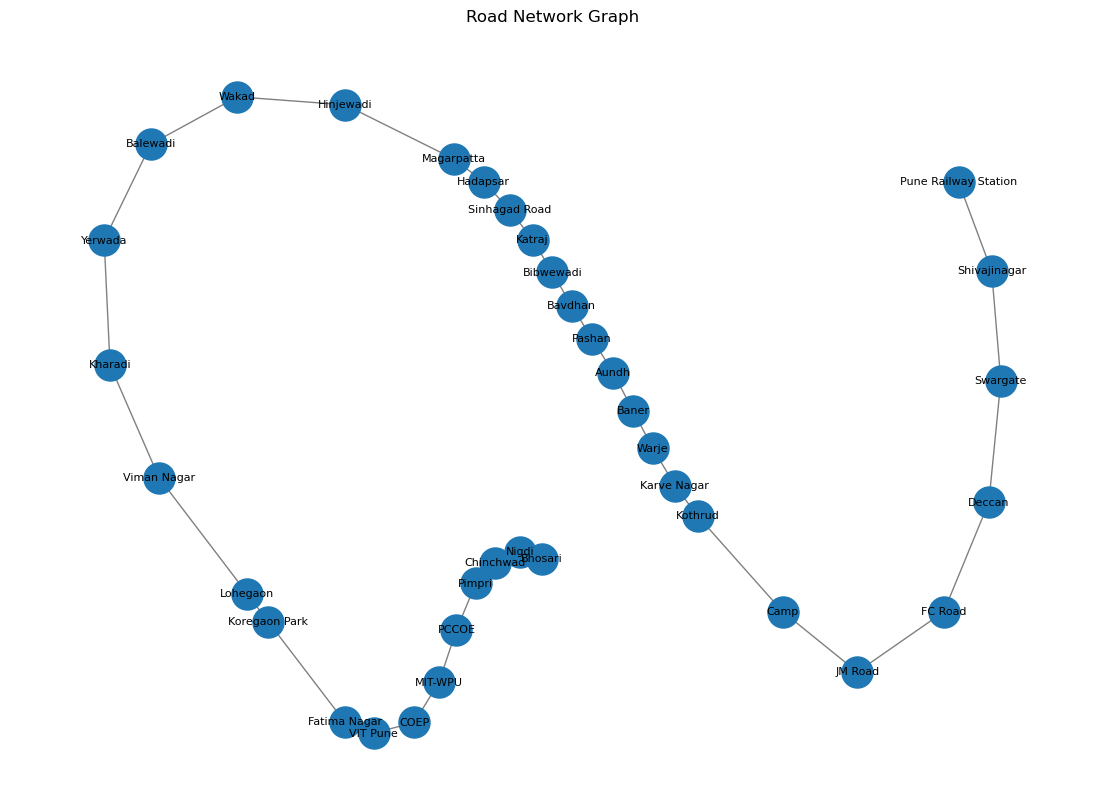

In [15]:
plt.figure(figsize=(14,10))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_size=500,
    font_size=8,
    edge_color="gray"
)

plt.title("Road Network Graph")

plt.axis("off")

plt.show()

In [16]:
source = "Pune Railway Station"
destination = "VIT Pune"

print(nx.has_path(G, source, destination))

True


In [17]:
# ==========================================
# User Input
# ==========================================

source = "Pune Railway Station"

destination = "VIT Pune"

print("Source      :", source)
print("Destination :", destination)

Source      : Pune Railway Station
Destination : VIT Pune


In [18]:
# ==========================================
# Dijkstra Algorithm
# ==========================================

path = nx.dijkstra_path(
    G,
    source,
    destination,
    weight="weight"
)

print("Safest Route:\n")

for location in path:
    print(location)

Safest Route:

Pune Railway Station
Shivajinagar
Swargate
Deccan
FC Road
JM Road
Camp
Kothrud
Karve Nagar
Warje
Baner
Aundh
Pashan
Bavdhan
Bibwewadi
Katraj
Sinhagad Road
Hadapsar
Magarpatta
Hinjewadi
Wakad
Balewadi
Yerwada
Kharadi
Viman Nagar
Lohegaon
Koregaon Park
Fatima Nagar
VIT Pune


In [19]:
# ==========================================
# Total Safety Cost
# ==========================================

total_cost = nx.dijkstra_path_length(
    G,
    source,
    destination,
    weight="weight"
)

print("Total Safety Cost :", round(total_cost,2))

Total Safety Cost : 342.6


In [20]:
# ==========================================
# Total Distance
# ==========================================

distance = 0

for i in range(len(path)-1):

    distance += G[path[i]][path[i+1]]["distance"]

print("Total Distance :", round(distance,2), "km")

Total Distance : 143.68 km


In [21]:
# ==========================================
# Average Safety Score
# ==========================================

scores = []

for i in range(len(path)-1):

    scores.append(
        G[path[i]][path[i+1]]["safety"]
    )

avg_score = sum(scores)/len(scores)

print("Average Safety Score :", round(avg_score,2))

Average Safety Score : 88.76


In [22]:
# ==========================================
# Route Safety Level
# ==========================================

if avg_score >= 70:

    level = "🟢 SAFE"

elif avg_score >= 40:

    level = "🟡 MODERATE"

else:

    level = "🔴 UNSAFE"

print("Recommended Route :", level)

Recommended Route : 🟢 SAFE


In [23]:
# ==========================================
# Route Summary
# ==========================================

print("="*50)

print("        SAFEPATH AI")

print("="*50)

print()

print("Source      :", source)

print("Destination :", destination)

print()

print("Recommended Route")

print("---------------------------")

for i in path:

    print("➡", i)

print()

print("---------------------------")

print("Distance :", round(distance,2), "km")

print("Safety Score :", round(avg_score,2))

print("Safety Cost :", round(total_cost,2))

print("Safety Level :", level)

print("="*50)

        SAFEPATH AI

Source      : Pune Railway Station
Destination : VIT Pune

Recommended Route
---------------------------
➡ Pune Railway Station
➡ Shivajinagar
➡ Swargate
➡ Deccan
➡ FC Road
➡ JM Road
➡ Camp
➡ Kothrud
➡ Karve Nagar
➡ Warje
➡ Baner
➡ Aundh
➡ Pashan
➡ Bavdhan
➡ Bibwewadi
➡ Katraj
➡ Sinhagad Road
➡ Hadapsar
➡ Magarpatta
➡ Hinjewadi
➡ Wakad
➡ Balewadi
➡ Yerwada
➡ Kharadi
➡ Viman Nagar
➡ Lohegaon
➡ Koregaon Park
➡ Fatima Nagar
➡ VIT Pune

---------------------------
Distance : 143.68 km
Safety Score : 88.76
Safety Cost : 342.6
Safety Level : 🟢 SAFE


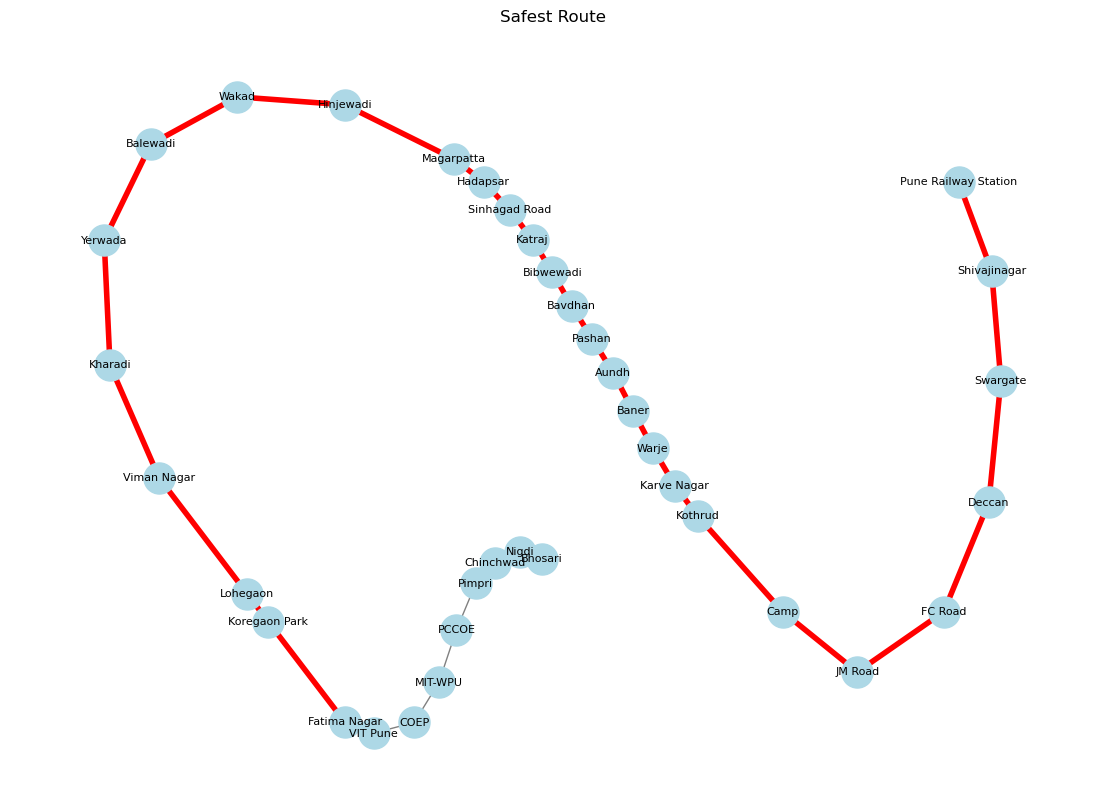

In [24]:
# ==========================================
# Visualize Route
# ==========================================

plt.figure(figsize=(14,10))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_size=500,
    node_color="lightblue",
    edge_color="gray",
    font_size=8
)

route_edges = list(zip(path[:-1], path[1:]))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=route_edges,
    edge_color="red",
    width=4
)

plt.title("Safest Route")

plt.axis("off")

plt.show()

In [25]:
# ==========================================
# Route Table
# ==========================================

route_details = []

for i in range(len(path)-1):

    edge = G[path[i]][path[i+1]]

    route_details.append({

        "From": path[i],

        "To": path[i+1],

        "Distance (km)": round(edge["distance"],2),

        "Safety Score": round(edge["safety"],2),

        "Edge Weight": round(edge["weight"],2)

    })

route_table = pd.DataFrame(route_details)

route_table

,From,To,Distance (km),Safety Score,Edge Weight
0,Pune Railway Station,Shivajinagar,3.31,99.60,1.40
1,Shivajinagar,Swargate,3.90,99.54,1.46
2,Swargate,Deccan,3.19,99.70,1.30
3,Deccan,FC Road,0.12,99.73,1.27
4,FC Road,JM Road,0.44,99.59,1.41
5,JM Road,Camp,4.04,99.66,1.34
6,Camp,Kothrud,8.03,99.62,1.38
7,Kothrud,Karve Nagar,2.09,75.92,25.08
8,Karve Nagar,Warje,1.73,77.57,23.43
9,Warje,Baner,7.65,75.54,25.46


## Route Recommendation Results

A weighted graph was created where each node represents a Pune location and each edge represents a road segment.

The edge weight was calculated using the Safety Score:

Edge Weight = 101 − Safety Score

The Dijkstra algorithm was applied to identify the route with the minimum safety cost.

The system returns:

- Recommended Route
- Total Distance
- Average Safety Score
- Overall Safety Level

This combines machine learning predictions with graph algorithms to recommend the safest route instead of simply the shortest route.